# Scenario Comparison -- 4 Algorithms Side by Side

Compare final policies, bid evolution, and network outcomes across up to 4 scenarios.
Edit `SCENARIOS` below to select which runs to compare.

In [16]:
import sys, os, importlib
from datetime import timedelta

import numpy as np
import pandas as pd
import yaml
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors

# ── Presentation font sizes ──────────────────────────────────────────────────
FONT_BODY   = 12
FONT_TITLE  = 13
FONT_SUPTITLE = 14
FONT_TICK   = 10
FONT_LEGEND = 9
SAVE_DPI    = 300
FIG_W = 12.0   # wider for side-by-side

matplotlib.rcParams.update({
    'font.size':        FONT_BODY,
    'axes.titlesize':   FONT_TITLE,
    'axes.labelsize':   FONT_BODY,
    'xtick.labelsize':  FONT_TICK,
    'ytick.labelsize':  FONT_TICK,
    'legend.fontsize':  FONT_LEGEND,
    'figure.titlesize': FONT_SUPTITLE,
    'figure.dpi':       SAVE_DPI,
    'savefig.dpi':      SAVE_DPI,
    'savefig.bbox':     'tight',
    'lines.linewidth':  1.5,
    'lines.markersize': 4,
    'axes.linewidth':   0.8,
    'grid.linewidth':   0.5,
})

# ── Path setup ────────────────────────────────────────────────────────────────
testbed_dir = os.path.abspath('.')
repo_root = os.path.abspath('..')
for p in [testbed_dir, repo_root]:
    if p not in sys.path:
        sys.path.insert(0, p)

from ieee9_network import build_ieee9_network
from clearing.sced_clearing import clear_sced
from learning_runner import _apply_generator_overrides, _apply_line_overrides

import nodal_plot
importlib.reload(nodal_plot)
from nodal_plot import (
    plot_nodal_circlize, plot_network_topology,
    assign_bus_colors, compute_ptdf_flows,
    BUS_PALETTE, TRANSIT_COLOR,
)

# ═══════════════════════════════════════════════════════════════════════════════
# CONFIG -- edit these to select which scenarios to compare
# ═══════════════════════════════════════════════════════════════════════════════
SCENARIOS = [
    'base_profit_matd3',
    'base_profit_sac',
    'base_profit_dmatd3',
    'base_profit_dsac',
]

# Short labels for plot titles/legends (auto-generated from scenario name if not provided)
LABELS = {}  # e.g. {'base_profit_matd3': 'MATD3'} -- leave empty for auto

PLOT_HOUR = 12
FOCUS_AGENT = 'gen_0'

# Colours for each scenario in comparison plots
SCENARIO_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# ═══════════════════════════════════════════════════════════════════════════════
# LOAD DATA
# ═══════════════════════════════════════════════════════════════════════════════
with open('scenarios.yaml') as f:
    all_scenarios = yaml.safe_load(f)

# Network metadata (shared across scenarios)
_network_meta = build_ieee9_network(periods=1)
_gen_df = _network_meta.generators
gen_mc = {name: float(row['marginal_cost']) for name, row in _gen_df.iterrows()}
gen_bus = {name: str(row['bus']) for name, row in _gen_df.iterrows()}
gen_capacity = {name: float(row['p_nom']) for name, row in _gen_df.iterrows()}

def _auto_label(scen_name, cfg):
    """Derive a short label from the scenario name."""
    # Strip common prefixes
    s = scen_name
    for prefix in ('base_profit_', 'congested_'):
        if s.startswith(prefix):
            s = s[len(prefix):]
            if prefix == 'congested_':
                s = s.upper() + ' (cong)'
                return s
    return s.upper()

# Load per-scenario data
scenario_data = {}
for i, scen_name in enumerate(SCENARIOS):
    assert scen_name in all_scenarios, f'{scen_name} not found in scenarios.yaml'
    cfg = all_scenarios[scen_name]
    tr = cfg['training']
    algo = tr.get('algorithm', 'matd3')
    results_dir = '../' + tr.get('results_dir', f'testbed_results/rl_{algo}')
    label = LABELS.get(scen_name, _auto_label(scen_name, cfg))

    # Final policy bids
    fp_path = f'{results_dir}/final_policy_bids.csv'
    fp_bids = None
    if os.path.exists(fp_path):
        fp_bids = pd.read_csv(fp_path, parse_dates=['timestamp'])
        fp_bids['hour'] = fp_bids['timestamp'].dt.hour

    # Final policy results (dispatch + LMP)
    fr_path = f'{results_dir}/final_policy_results.csv'
    fp_results = None
    if os.path.exists(fr_path):
        fp_results = pd.read_csv(fr_path, parse_dates=['timestamp'])
        fp_results['hour'] = fp_results['timestamp'].dt.hour

    # Bid history (training trajectory)
    bh_path = f'{results_dir}/bid_history.csv'
    bid_history = None
    if os.path.exists(bh_path):
        bid_history = pd.read_csv(bh_path, parse_dates=['timestamp'])
        bid_history['hour'] = bid_history['timestamp'].dt.hour

    scenario_data[scen_name] = {
        'cfg': cfg,
        'algorithm': algo,
        'label': label,
        'results_dir': results_dir,
        'color': SCENARIO_COLORS[i % len(SCENARIO_COLORS)],
        'fp_bids': fp_bids,
        'fp_results': fp_results,
        'bid_history': bid_history,
    }
    n_eps = bid_history['episode'].nunique() if bid_history is not None else 0
    print(f'{label:16s} ({scen_name}): {results_dir}  [{n_eps} episodes]')

print(f'\nPlot hour: {PLOT_HOUR}  |  Focus agent: {FOCUS_AGENT}')

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
MATD3            (base_profit_matd3): ../testbed_results/rl_matd3  [1000 episodes]
SAC              (base_profit_sac): ../testbed_results/rl_sac  [1000 episodes]
DMATD3           (base_profit_dmatd3): ../testbed_results/rl_dmatd3  [1000 episodes]
DSAC             (base_profit_dsac): ../testbed_results/rl_dsac  [1000 episodes]

Plot hour: 12  |  Focus agent: gen_0


## Chart 1 -- Final Policy by Hour (Price + Volume)

All 24 hours, all scenarios overlaid. Price on left axis, volume on right.

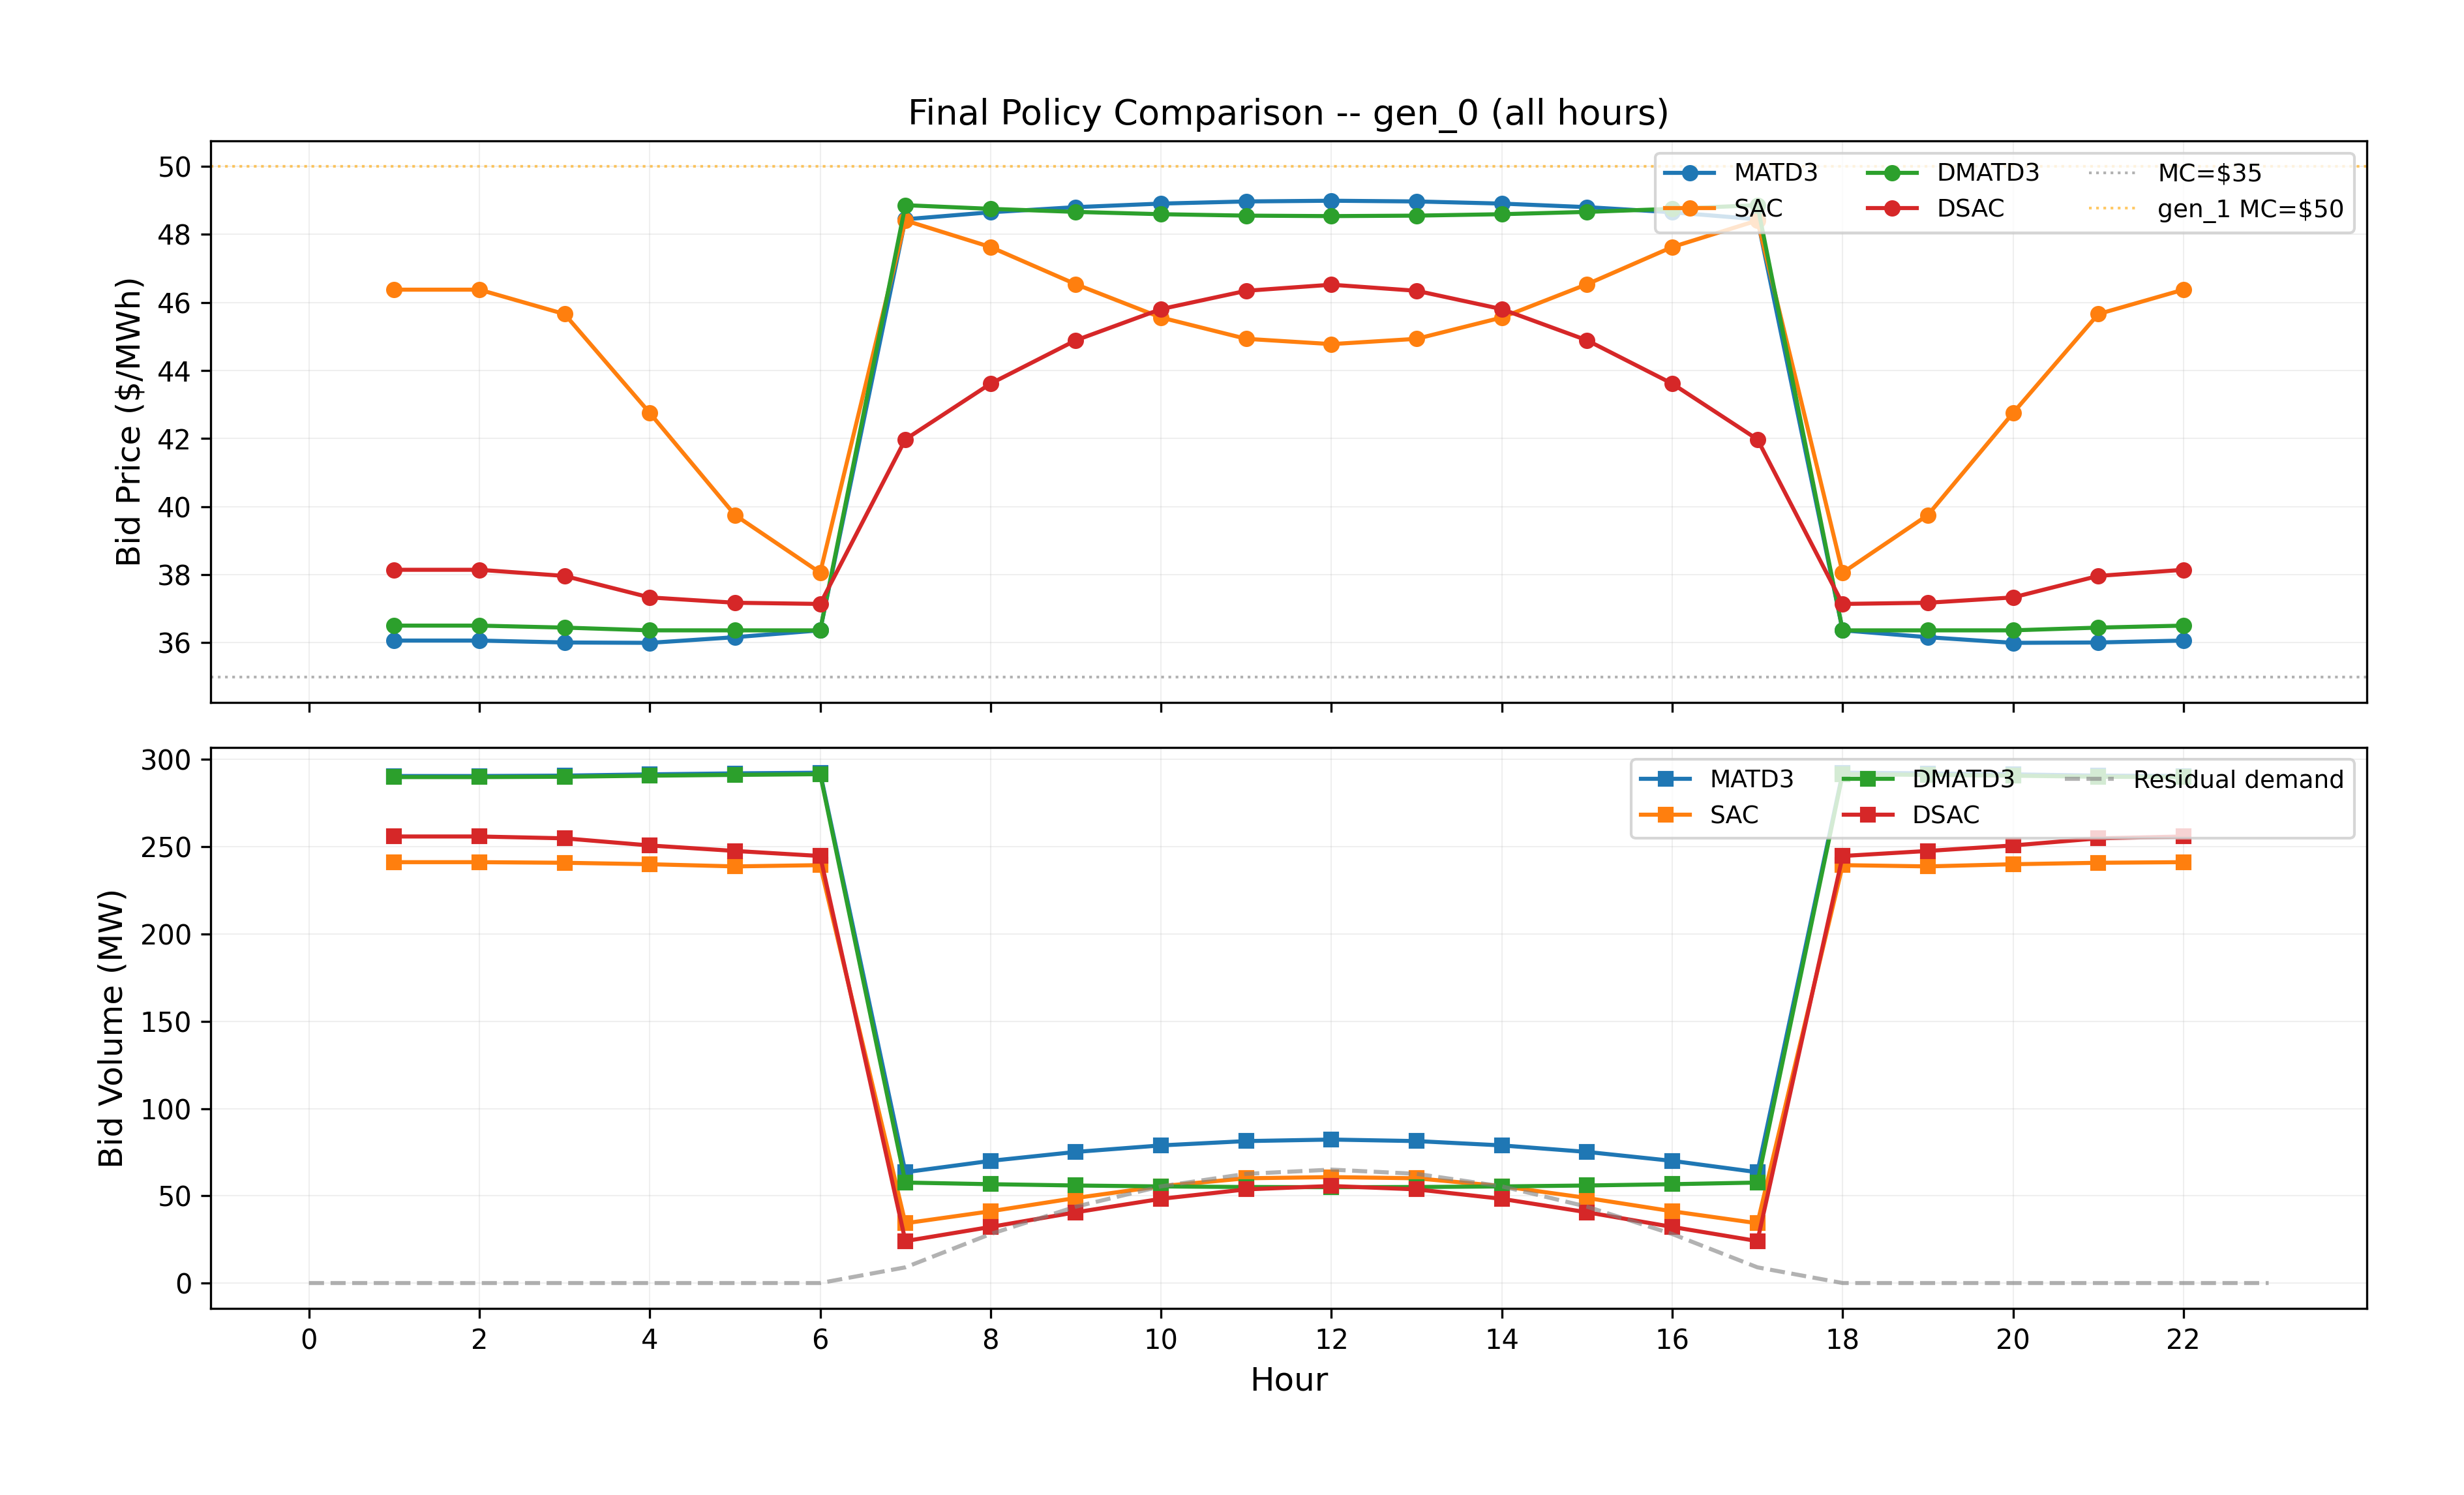


Final Policy at H12:
   Algorithm       Price      Volume    Dispatch       LMP    Profit/h
----------------------------------------------------------------------
       MATD3  $     49.0         82 MW         65 MW  $   49.0  $      909/h
         SAC  $     44.8         61 MW         61 MW  $   50.0  $      911/h
      DMATD3  $     48.5         55 MW         55 MW  $   50.0  $      824/h
        DSAC  $     46.5         56 MW         56 MW  $   50.0  $      834/h


In [17]:
fig, (ax_p, ax_v) = plt.subplots(2, 1, figsize=(FIG_W, 7), sharex=True)

hours = list(range(24))

for scen_name in SCENARIOS:
    sd = scenario_data[scen_name]
    fp = sd['fp_bids']
    if fp is None:
        continue
    agent_fp = fp[fp['unit_id'] == FOCUS_AGENT].sort_values('hour')
    if agent_fp.empty:
        continue

    ax_p.plot(agent_fp['hour'], agent_fp['bid_price'],
              '-o', color=sd['color'], label=sd['label'], markersize=5)
    ax_v.plot(agent_fp['hour'], agent_fp['bid_volume'],
              '-s', color=sd['color'], label=sd['label'], markersize=5)

# Reference lines
mc_agent = gen_mc.get(FOCUS_AGENT, 35.0)
ax_p.axhline(mc_agent, color='gray', ls=':', lw=1, alpha=0.6, label=f'MC=${mc_agent:.0f}')
ax_p.axhline(50.0, color='orange', ls=':', lw=1, alpha=0.6, label='gen_1 MC=$50')

# Residual demand profile
_pcfg = all_scenarios[SCENARIOS[0]]['profile']
_t = np.arange(24)
_raw = _pcfg['base'] + _pcfg['amplitude'] * np.sin(
    2 * np.pi * (_t - _pcfg['phase_shift']) / _pcfg['period'])
_profile = np.clip(_raw, _pcfg['clip_min'], _pcfg['clip_max'])
_demand = 315 * _profile
_residual = np.maximum(0.0, _demand - 250.0)
ax_v.plot(hours, _residual, '--', color='gray', lw=1.5, alpha=0.6, label='Residual demand')

ax_p.set_ylabel('Bid Price ($/MWh)')
ax_p.set_title(f'Final Policy Comparison -- {FOCUS_AGENT} (all hours)')
ax_p.legend(loc='upper right', ncol=3)
ax_p.grid(True, alpha=0.2)

ax_v.set_ylabel('Bid Volume (MW)')
ax_v.set_xlabel('Hour')
ax_v.legend(loc='upper right', ncol=3)
ax_v.grid(True, alpha=0.2)
ax_v.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig(f'../testbed_results/compare_final_policy.png', bbox_inches='tight')
plt.show()

# ── Numerical summary table ──────────────────────────────────────────────────
print(f'\nFinal Policy at H{PLOT_HOUR:02d}:')
print(f'{"Algorithm":>12s}  {"Price":>10s}  {"Volume":>10s}  {"Dispatch":>10s}  {"LMP":>8s}  {"Profit/h":>10s}')
print('-' * 70)
for scen_name in SCENARIOS:
    sd = scenario_data[scen_name]
    fp = sd['fp_bids']
    fr = sd['fp_results']
    if fp is None:
        continue
    h_bid = fp[(fp['unit_id'] == FOCUS_AGENT) & (fp['hour'] == PLOT_HOUR)]
    h_res = fr[(fr['unit_id'] == FOCUS_AGENT) & (fr['hour'] == PLOT_HOUR)] if fr is not None else pd.DataFrame()
    if h_bid.empty:
        continue
    bp = h_bid.iloc[0]['bid_price']
    bv = h_bid.iloc[0]['bid_volume']
    if not h_res.empty:
        lmp = h_res.iloc[0]['accepted_price']
        disp = h_res.iloc[0]['dispatch']
        profit = (lmp - mc_agent) * disp
    else:
        lmp = disp = profit = float('nan')
    print(f'{sd["label"]:>12s}  ${bp:9.1f}  {bv:9.0f} MW  {disp:9.0f} MW  ${lmp:7.1f}  ${profit:9.0f}/h')

## Chart 2 -- Landscape Journey (Bid Evolution at Focus Hour)

Training bids on the **true** profit surface for each scenario at `PLOT_HOUR`.
The surface is computed by sweeping actual SCED clears across a grid of
(price, volume) bid points, so it correctly reflects congestion effects.
2x2 grid, one panel per scenario.

In [ ]:
# ── True profit surface via SCED sweep ────────────────────────────────────────
# For each scenario, sweep a grid of (price, volume) bids for FOCUS_AGENT
# at PLOT_HOUR, running actual SCED with congestion constraints.
# All other generators bid at marginal cost.
#
# Results are cached as .npz files in the results directory so subsequent
# runs skip the SCED sweep. Delete the .npz to force recomputation.

import warnings
import logging
logging.getLogger('egret').setLevel(logging.WARNING)
logging.getLogger('highspy').setLevel(logging.WARNING)

_scen0 = all_scenarios[SCENARIOS[0]]
_g0 = _scen0['generators']['gen_0']
PRICE_CAP = float(_g0.get('price_cap', 60.0))
P_MAX_0 = float(_g0['p_max'])
MC_0 = float(_g0['price'])
MC_1 = float(_scen0['generators']['gen_1']['price'])

# Grid resolution (coarser than analytical surface for speed)
N_GRID = 40
price_ax = np.linspace(0.5, PRICE_CAP, N_GRID)
vol_ax = np.linspace(0.02, 1.0, N_GRID)

def compute_sced_profit_surface(scen_name, hour=PLOT_HOUR):
    """Sweep SCED across (price, vol) grid for FOCUS_AGENT at one hour."""
    cfg = all_scenarios[scen_name]
    pcfg = cfg.get('profile', {})
    net = build_ieee9_network(start='2025-01-01', periods=24, profile_cfg=pcfg)
    _apply_generator_overrides(net, cfg.get('generators', {}))
    _apply_line_overrides(net, cfg.get('line_overrides', {}))

    gen_df = net.generators.copy()
    gen_df.rename(columns={'bus': 'node', 'p_nom': 'max_power'}, inplace=True)
    loads_df = net.loads.copy()
    loads_df.rename(columns={'bus': 'node', 'p_set': 'min_power'}, inplace=True)
    grid_data = {
        'buses': net.buses, 'lines': net.lines,
        'generators': gen_df, 'loads': loads_df,
    }

    ts = net.snapshots[hour]
    t_start = ts.to_pydatetime()
    t_end = t_start + timedelta(hours=1)
    mc_agent = float(gen_df.at[FOCUS_AGENT, 'marginal_cost'])

    profit_grid = np.zeros((N_GRID, N_GRID))

    for pi, bp in enumerate(price_ax):
        for vi, vf in enumerate(vol_ax):
            bv = vf * P_MAX_0
            orderbook = []
            for gname, gen in gen_df.iterrows():
                if gname == FOCUS_AGENT:
                    p, v = bp, bv
                else:
                    p = float(gen['marginal_cost'])
                    v = float(gen['max_power'])
                orderbook.append({
                    'start_time': t_start, 'end_time': t_end, 'only_hours': None,
                    'price': p, 'volume': v,
                    'node': gen['node'], 'unit_id': gname,
                    'bid_id': f'{gname}_0',
                })
            for lname in net.loads.index:
                if lname in net.loads_t.p_set.columns:
                    d = float(net.loads_t.p_set.at[ts, lname])
                else:
                    d = float(loads_df.at[lname, 'min_power'])
                orderbook.append({
                    'start_time': t_start, 'end_time': t_end, 'only_hours': None,
                    'price': 1000.0, 'volume': -d,
                    'node': net.loads.at[lname, 'bus'],
                    'unit_id': lname, 'bid_id': f'{lname}_0',
                })

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                try:
                    acc, rej, meta, flows = clear_sced(
                        orderbook, [(t_start, t_end, None)], grid_data, solver='highs')
                    agent_dispatch = 0.0
                    bus_lmps = meta[0].get('bus_lmps', {})
                    agent_bus = gen_df.at[FOCUS_AGENT, 'node']
                    lmp = bus_lmps.get(str(agent_bus), bus_lmps.get(agent_bus, 0.0))
                    for o in acc:
                        if o['unit_id'] == FOCUS_AGENT:
                            agent_dispatch += o.get('accepted_volume', 0)
                    profit_grid[vi, pi] = (lmp - mc_agent) * agent_dispatch
                except Exception:
                    profit_grid[vi, pi] = 0.0

    return profit_grid

def load_or_compute_surface(scen_name):
    """Load cached .npz if available, otherwise compute and save."""
    sd = scenario_data[scen_name]
    cache_path = f'{sd["results_dir"]}/profit_surface_h{PLOT_HOUR:02d}.npz'
    if os.path.exists(cache_path):
        data = np.load(cache_path)
        # Verify grid matches
        if (data['price_ax'].shape == price_ax.shape and
            data['vol_ax'].shape == vol_ax.shape and
            np.allclose(data['price_ax'], price_ax) and
            np.allclose(data['vol_ax'], vol_ax)):
            print(f'  {sd["label"]}: loaded from cache ({cache_path})')
            return data['profit_grid']
        else:
            print(f'  {sd["label"]}: cache grid mismatch, recomputing...')

    print(f'  {sd["label"]}: computing SCED sweep ({N_GRID}x{N_GRID})...', end=' ', flush=True)
    grid = compute_sced_profit_surface(scen_name)
    # Save cache
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    np.savez_compressed(cache_path, profit_grid=grid, price_ax=price_ax, vol_ax=vol_ax,
                        hour=PLOT_HOUR, scenario=scen_name, agent=FOCUS_AGENT, n_grid=N_GRID)
    print(f'done (max=${grid.max():.0f}/h, saved to {cache_path})')
    return grid

# Compute or load surfaces
print('Loading/computing profit surfaces:')
profit_surfaces = {}
for scen_name in SCENARIOS:
    profit_surfaces[scen_name] = load_or_compute_surface(scen_name)

# ── Demand info for title ─────────────────────────────────────────────────────
_pcfg = all_scenarios[SCENARIOS[0]]['profile']
_t = np.arange(24)
_raw = _pcfg['base'] + _pcfg['amplitude'] * np.sin(
    2 * np.pi * (_t - _pcfg['phase_shift']) / _pcfg['period'])
_profile = np.clip(_raw, _pcfg['clip_min'], _pcfg['clip_max'])
_demand = 315 * _profile
D_h = float(_demand[PLOT_HOUR])
P_MAX_S = float(all_scenarios[SCENARIOS[0]]['generators']['gen_slack_0']['p_max'])
res_h = max(0.0, D_h - P_MAX_S)
vf_break = res_h / P_MAX_0 if P_MAX_0 > 0 else 0

# ── 2x2 grid: one panel per scenario ──────────────────────────────────────────
n_scen = len(SCENARIOS)
ncols = min(n_scen, 2)
nrows = (n_scen + 1) // 2
fig, axes = plt.subplots(nrows, ncols, figsize=(FIG_W, 5.5 * nrows))
if n_scen == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = axes[np.newaxis, :]

# Shared colour scale across all scenarios
global_max = max(ps.max() for ps in profit_surfaces.values())
global_min = min(ps.min() for ps in profit_surfaces.values())
vabs = max(abs(global_max), abs(global_min), 0.01)
norm = mcolors.TwoSlopeNorm(vmin=-vabs, vcenter=0.0, vmax=vabs)

for idx, scen_name in enumerate(SCENARIOS):
    sd = scenario_data[scen_name]
    row, col = divmod(idx, ncols)
    ax = axes[row, col]

    # True profit surface background
    im = ax.contourf(price_ax, vol_ax, profit_surfaces[scen_name],
                     levels=30, cmap='RdYlGn', norm=norm)
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)

    # Reference lines
    if vf_break > 0.01:
        ax.axhline(vf_break, color='gray', lw=0.8, ls=':', alpha=0.8,
                   label=f'Residual ({res_h:.0f} MW)')
    ax.axvline(MC_1, color='orange', lw=0.8, ls=':', alpha=0.8,
               label=f'gen_1 MC=${MC_1:.0f}')
    ax.plot(MC_0, 1.0, '*', color='deepskyblue', markersize=10, zorder=6,
            label='Comp. eq.')

    # Training bids
    bh = sd['bid_history']
    if bh is not None:
        hb = bh[(bh['hour'] == PLOT_HOUR) & (bh['unit_id'] == FOCUS_AGENT)]
        if len(hb) > 0:
            sc = ax.scatter(hb['bid_price'], hb['bid_volume'] / P_MAX_0,
                       c=hb['episode'], cmap='cool', s=8, alpha=0.5, zorder=5,
                       label='Training bids')

    # Final policy
    fp = sd['fp_bids']
    if fp is not None:
        fp_h = fp[(fp['hour'] == PLOT_HOUR) & (fp['unit_id'] == FOCUS_AGENT)]
        if not fp_h.empty:
            ax.plot(fp_h.iloc[0]['bid_price'], fp_h.iloc[0]['bid_volume'] / P_MAX_0,
                    'X', color='red', markersize=14, zorder=8,
                    markeredgecolor='darkred', markeredgewidth=1.5,
                    label='Final policy')

    ax.set_title(f'{sd["label"]}', fontsize=FONT_TITLE)
    ax.set_xlabel('Bid price ($/MWh)')
    ax.set_ylabel('Volume fraction')
    ax.legend(fontsize=7, loc='upper right')

# Hide unused axes
for idx in range(n_scen, nrows * ncols):
    row, col = divmod(idx, ncols)
    axes[row, col].set_visible(False)

fig.suptitle(f'Bid Evolution at H{PLOT_HOUR:02d} (D={D_h:.0f} MW, res={res_h:.0f} MW)\n'
             f'Background = true SCED profit surface | dots = training bids | X = final policy',
             fontsize=FONT_SUPTITLE)
plt.tight_layout()
plt.savefig(f'../testbed_results/compare_landscape_h{PLOT_HOUR:02d}.png', bbox_inches='tight')
plt.show()

## Chart 3 -- Circlize Diagrams (Final Policy at Focus Hour)

Network topology + circlize chord diagram for each scenario's final policy.
Re-runs SCED with each scenario's final bids to get dispatch + LMPs + flows.

In [19]:
def run_sced_for_scenario(scen_name):
    """Re-run SCED with a scenario's final policy bids. Returns accepted, rejected, meta, flows."""
    sd = scenario_data[scen_name]
    cfg = sd['cfg']
    fp_bids = sd['fp_bids']
    rl_agents = set(cfg['training'].get('rl_agents', []))

    pcfg = cfg.get('profile', {})
    periods = cfg.get('periods', 24)
    net = build_ieee9_network(start='2025-01-01', periods=periods, profile_cfg=pcfg)
    _apply_generator_overrides(net, cfg.get('generators', {}))
    _apply_line_overrides(net, cfg.get('line_overrides', {}))

    gen_df = net.generators.copy()
    gen_df.rename(columns={'bus': 'node', 'p_nom': 'max_power'}, inplace=True)
    loads_df = net.loads.copy()
    loads_df.rename(columns={'bus': 'node', 'p_set': 'min_power'}, inplace=True)

    grid_data = {
        'buses': net.buses, 'lines': net.lines,
        'generators': gen_df, 'loads': loads_df,
    }

    orderbook = []
    market_products = []
    for i, ts in enumerate(net.snapshots):
        start = ts.to_pydatetime()
        end = start + timedelta(hours=1)
        market_products.append((start, end, None))
        for gname, gen in gen_df.iterrows():
            if fp_bids is not None and gname in rl_agents:
                h = ts.hour
                fp_h = fp_bids[(fp_bids['unit_id'] == gname) & (fp_bids['hour'] == h)]
                if not fp_h.empty:
                    bp = float(fp_h.iloc[0]['bid_price'])
                    bv = float(fp_h.iloc[0]['bid_volume'])
                else:
                    bp = float(gen['marginal_cost'])
                    bv = float(gen['max_power'])
            else:
                bp = float(gen['marginal_cost'])
                bv = float(gen['max_power'])
            orderbook.append({
                'start_time': start, 'end_time': end, 'only_hours': None,
                'price': bp, 'volume': bv,
                'node': gen['node'], 'unit_id': gname,
                'bid_id': f'{gname}_{i}',
            })
        for lname in net.loads.index:
            if lname in net.loads_t.p_set.columns:
                d = float(net.loads_t.p_set.at[ts, lname])
            else:
                d = float(loads_df.at[lname, 'min_power'])
            orderbook.append({
                'start_time': start, 'end_time': end, 'only_hours': None,
                'price': 1000.0, 'volume': -d,
                'node': net.loads.at[lname, 'bus'],
                'unit_id': lname, 'bid_id': f'{lname}_{i}',
            })

    accepted, rejected, meta, flows = clear_sced(
        orderbook, market_products, grid_data, solver='highs')
    return net, accepted, rejected, meta, flows, market_products


# Run SCED for each scenario
sced_results = {}
for scen_name in SCENARIOS:
    print(f'Running SCED for {scenario_data[scen_name]["label"]}...')
    net, acc, rej, meta, flows, mkt_prods = run_sced_for_scenario(scen_name)
    sced_results[scen_name] = {
        'network': net, 'accepted': acc, 'rejected': rej,
        'meta': meta, 'flows': flows, 'market_products': mkt_prods,
    }
    avg_lmp = meta[PLOT_HOUR]['price']
    print(f'  H{PLOT_HOUR:02d} avg LMP: ${avg_lmp:.1f}')
print('Done.')

Running SCED for MATD3...
Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
INFO:learning_runner:Added generator 'gen_peaker_0': bus=1, p_max=50.0, price=60.0
INFO:learning_runner:Generator overrides applied: gen_0($35, 300MW), gen_1($50, 270MW), gen_slack_0($20, 250MW), gen_peaker_0($60, 50MW)
INFO:learning_runner:Line overrides applied: line_0(250MW), line_1(250MW), line_2(150MW), line_3(300MW), line_4(150MW), line_5(250MW), line_6(250MW), line_7(250MW), line_8(250MW)
INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 1119 rows; 1032 cols; 2060 nonzeros
Coefficient ranges:
  Matrix  [2e-01, 6e+03]
  Cost    [1e+00, 1e+08]
  Bound   [5

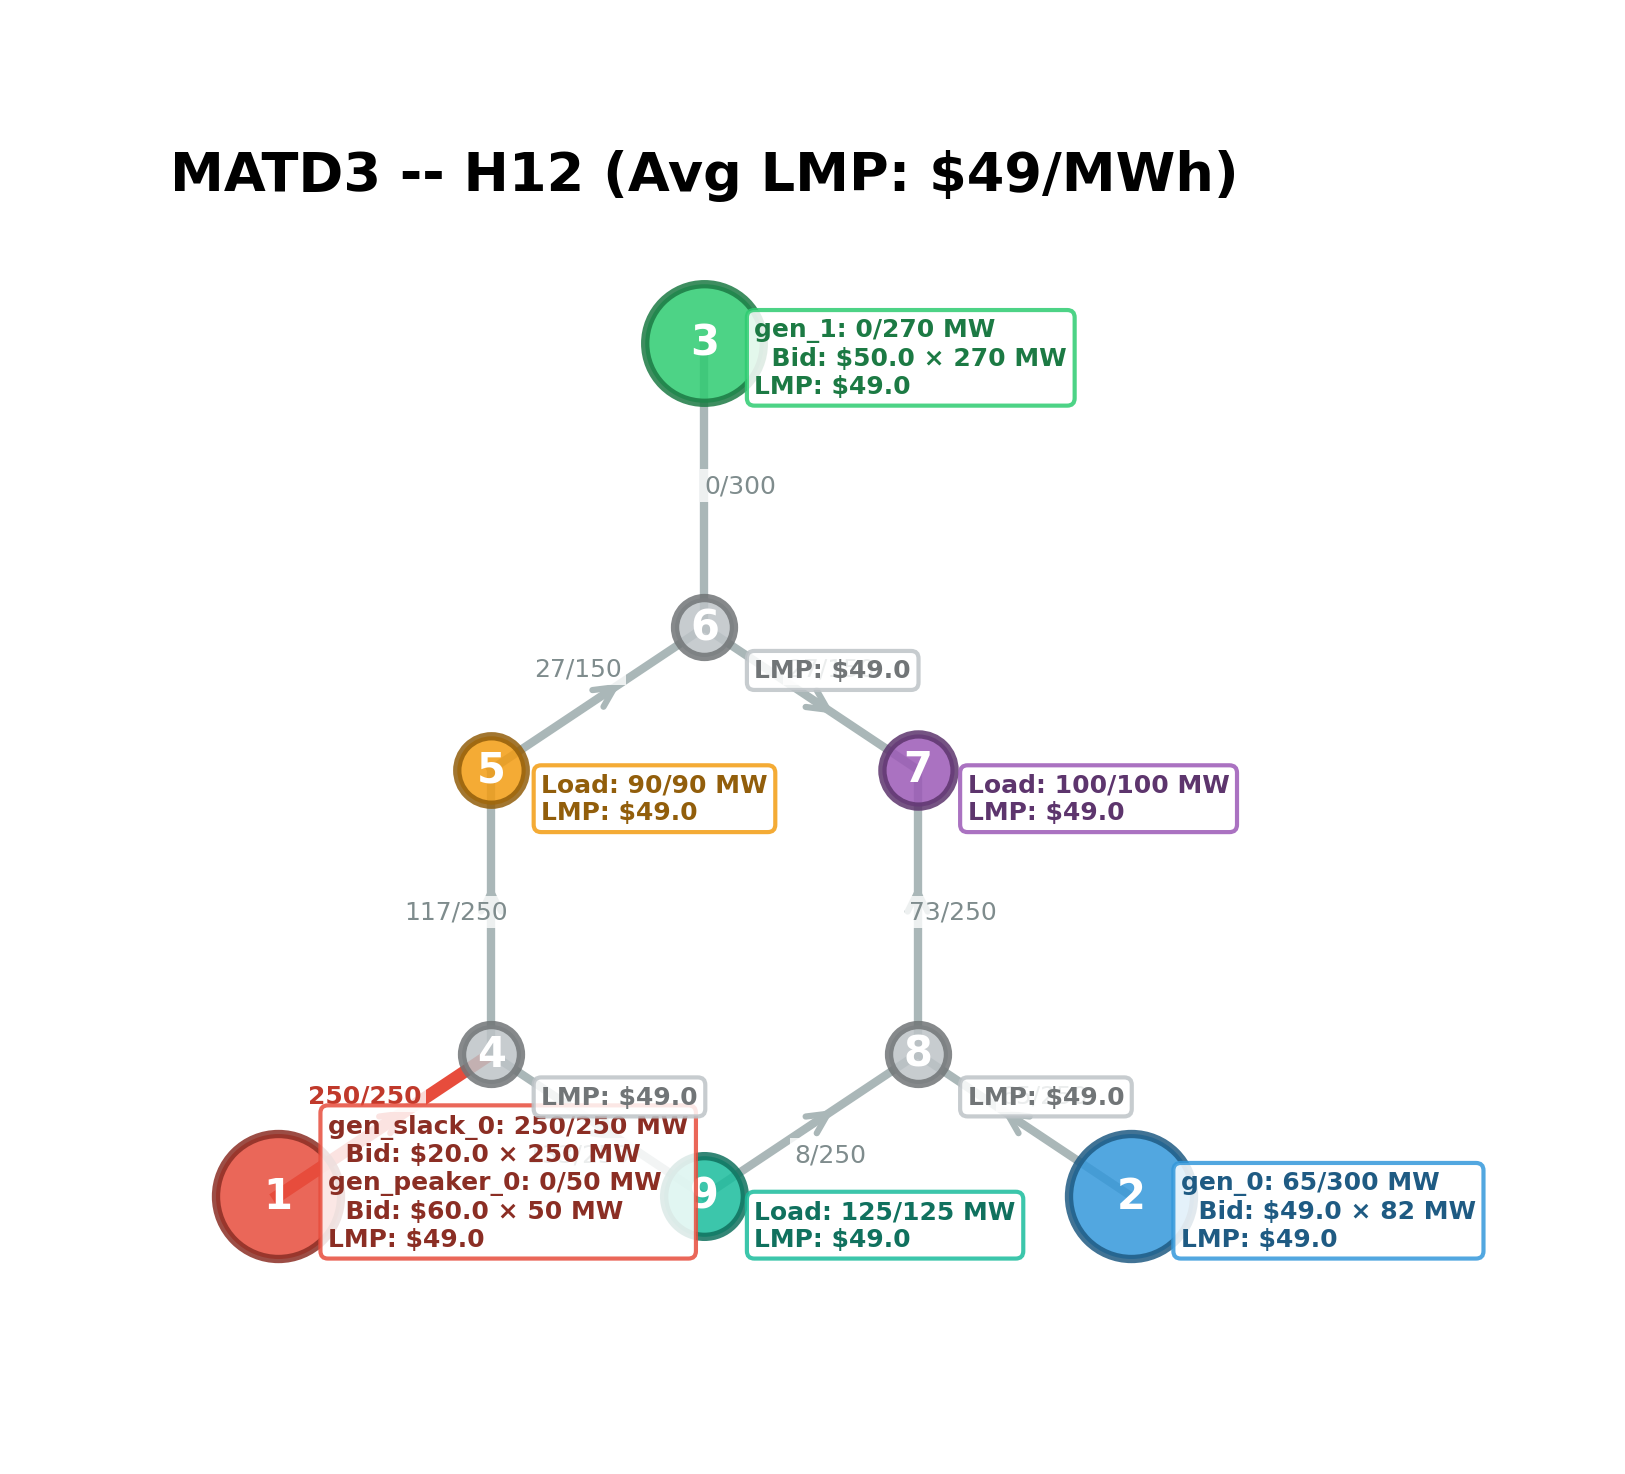

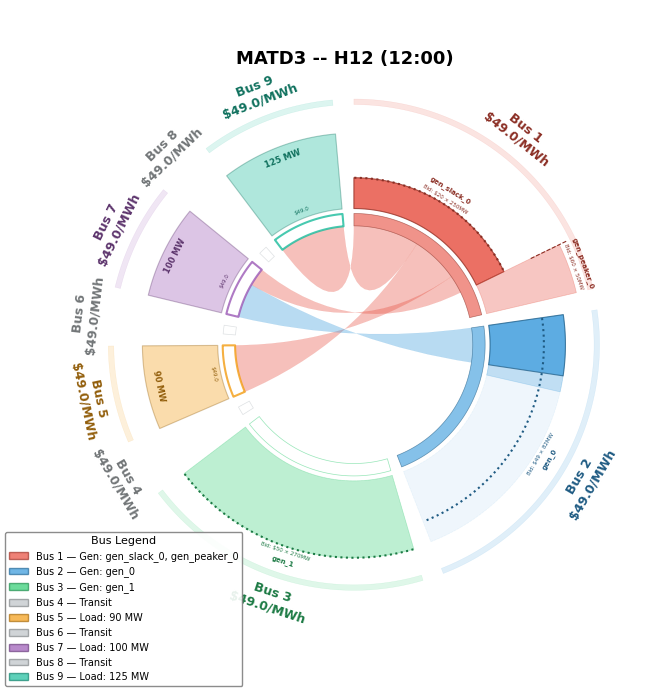

MATD3: LMPs = {'1': 48.99139881134033, '2': 48.99139881134033, '3': 48.99139881134033, '4': 48.99139881134033, '5': 48.99139881134033, '6': 48.99139881134033, '7': 48.99139881134033, '8': 48.99139881134033, '9': 48.99139881134033}



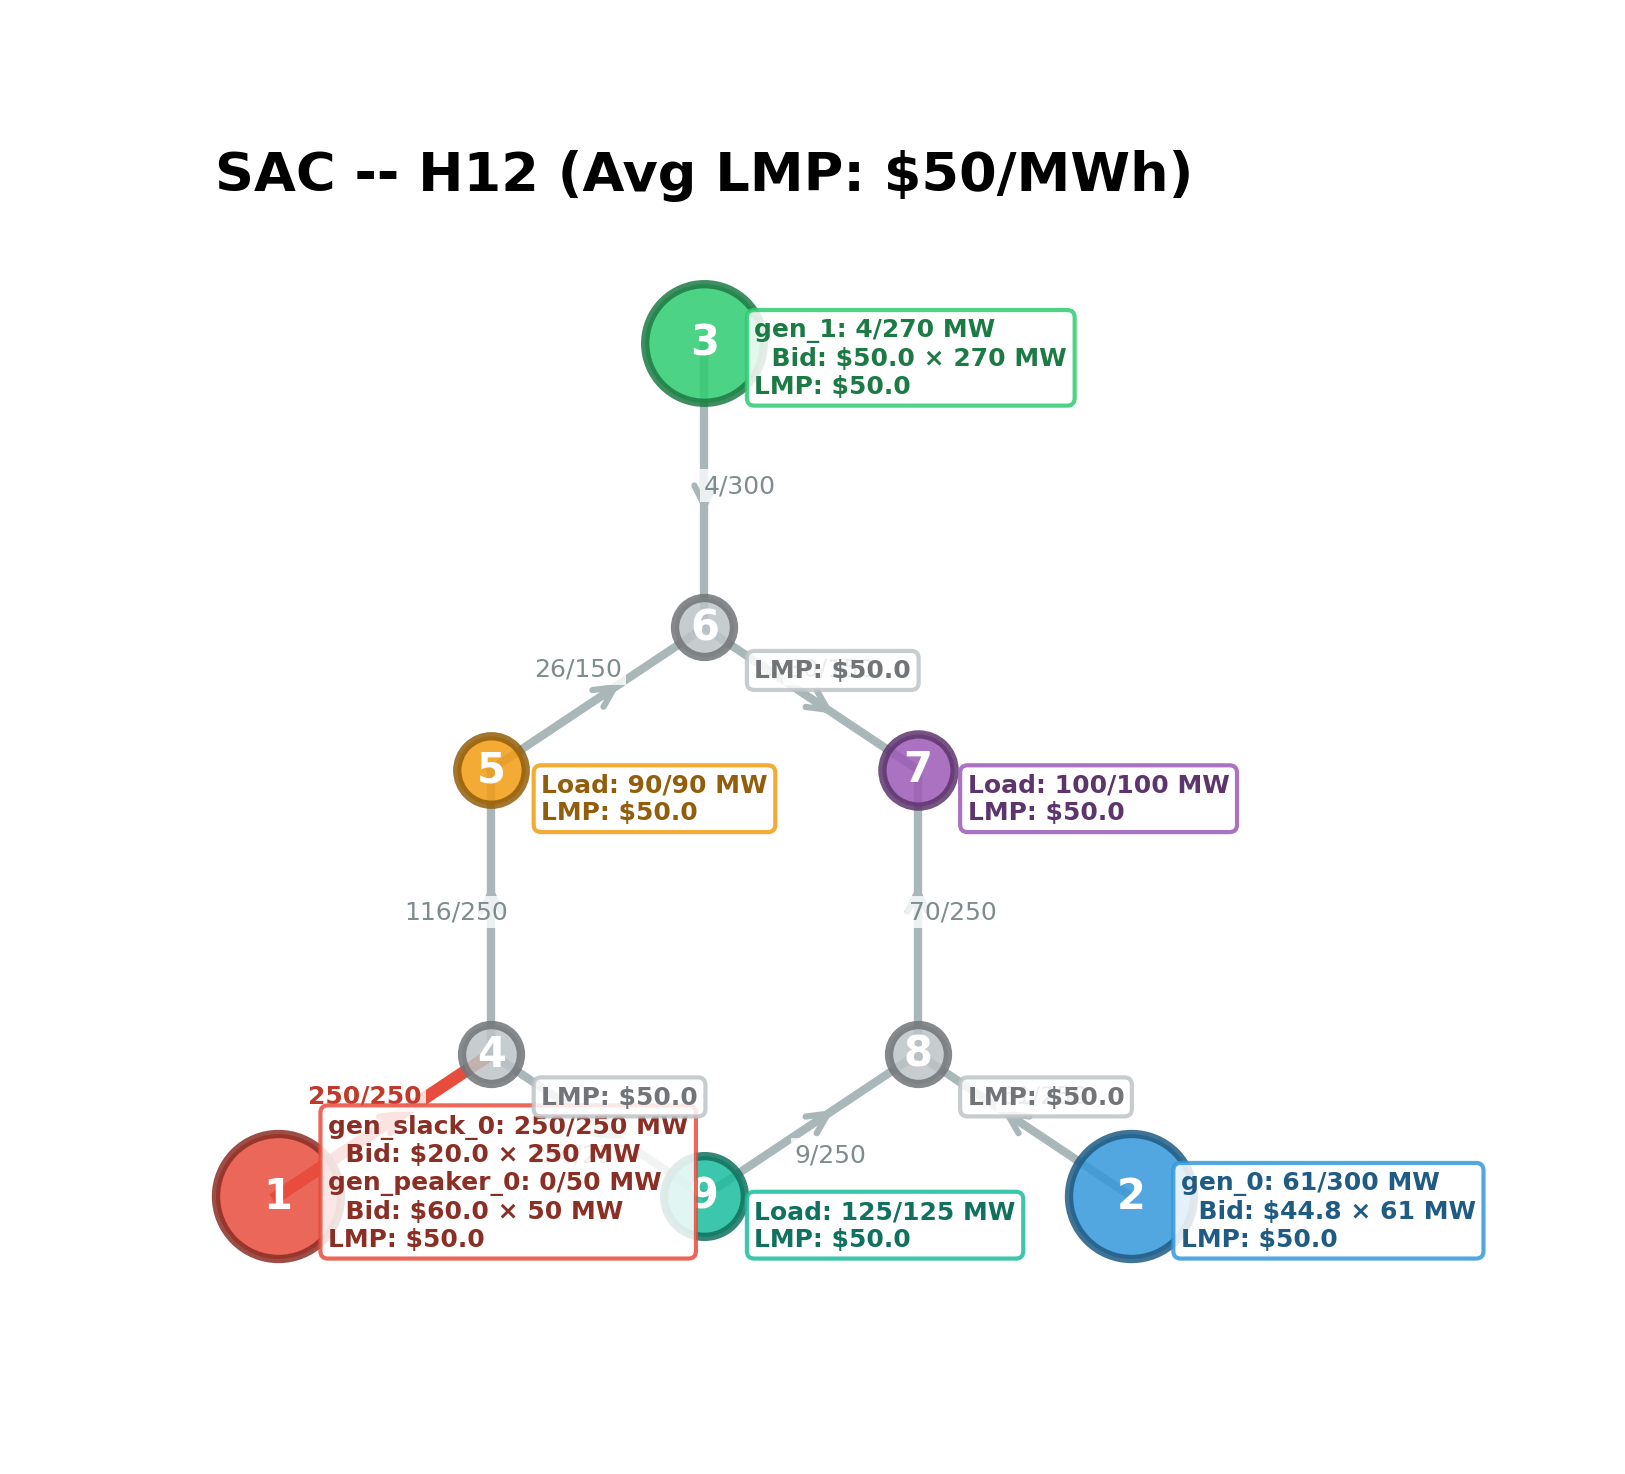

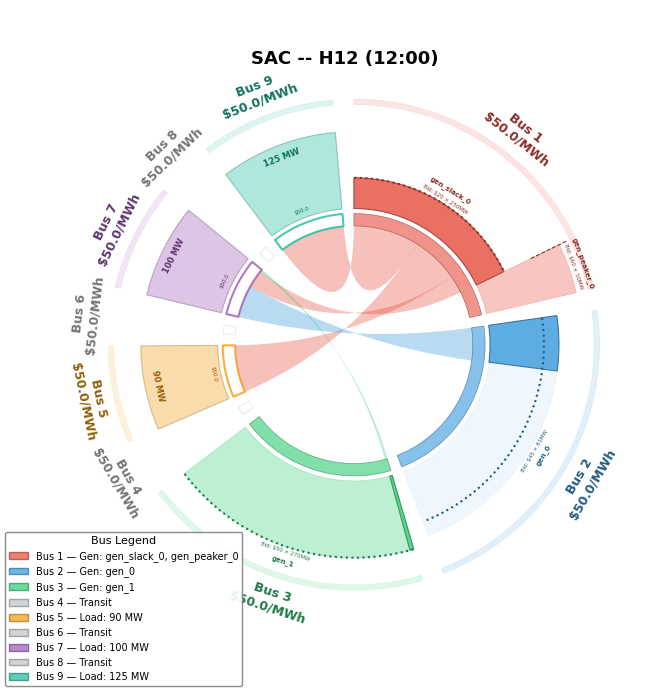

SAC: LMPs = {'1': 50.0, '2': 50.0, '3': 50.0, '4': 50.0, '5': 50.0, '6': 50.0, '7': 50.0, '8': 50.0, '9': 50.0}



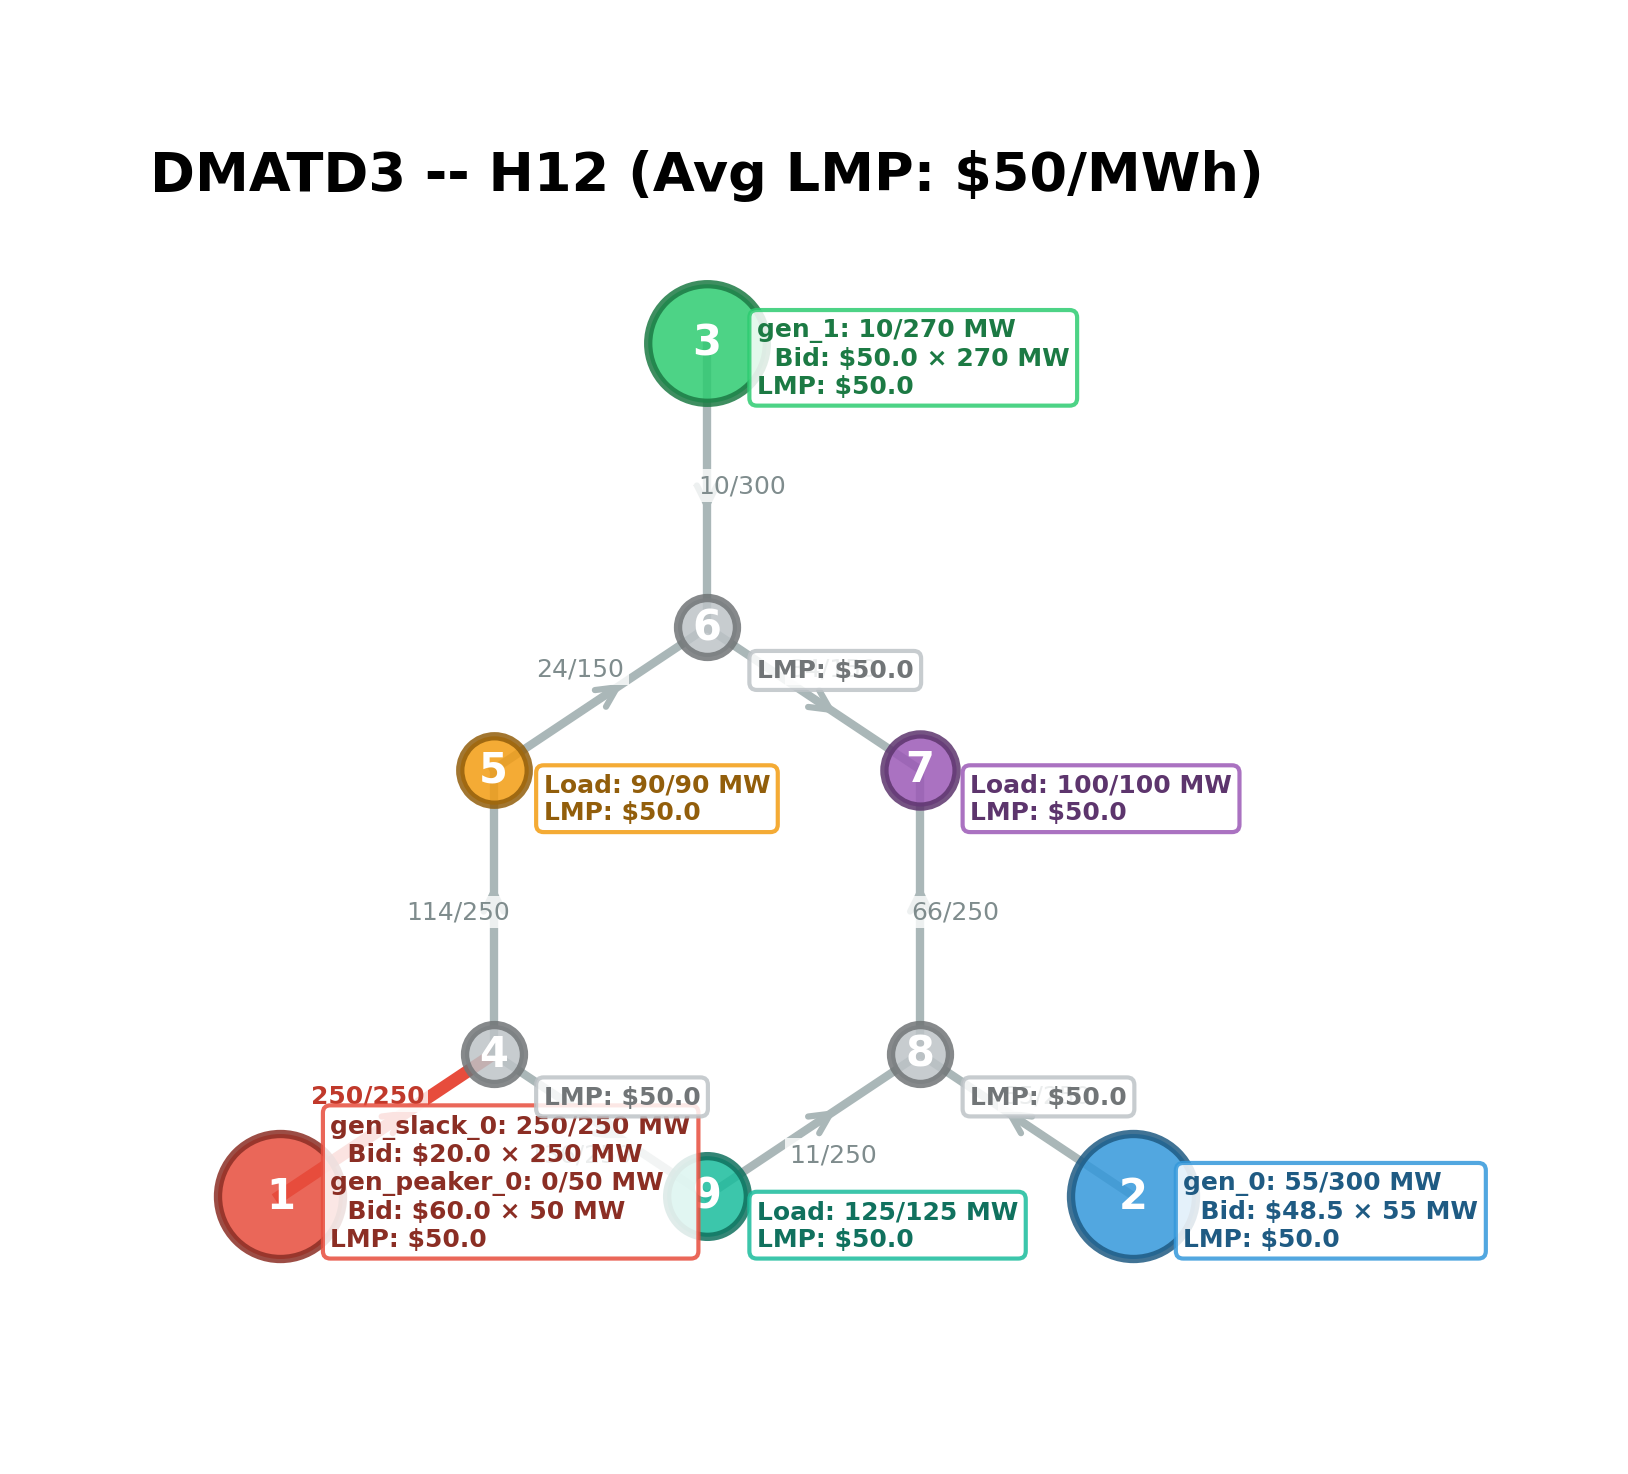

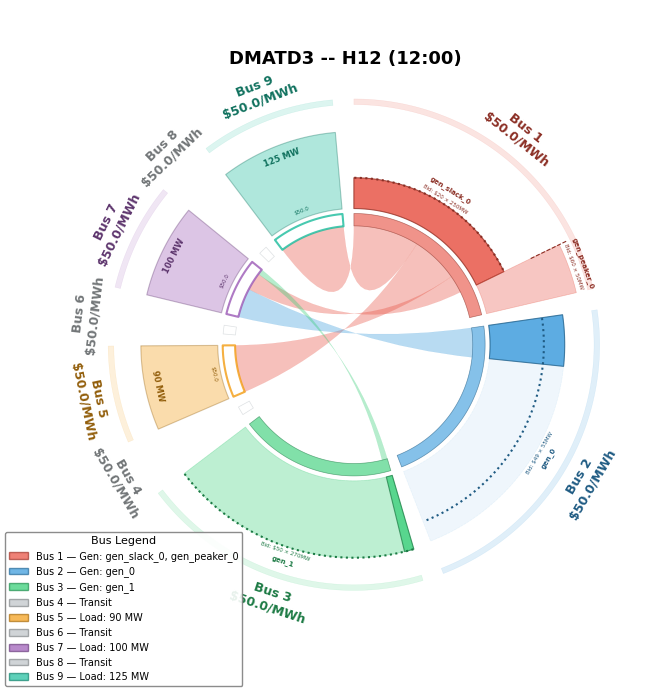

DMATD3: LMPs = {'1': 50.0, '2': 50.0, '3': 50.0, '4': 50.0, '5': 50.0, '6': 50.0, '7': 50.0, '8': 50.0, '9': 50.0}



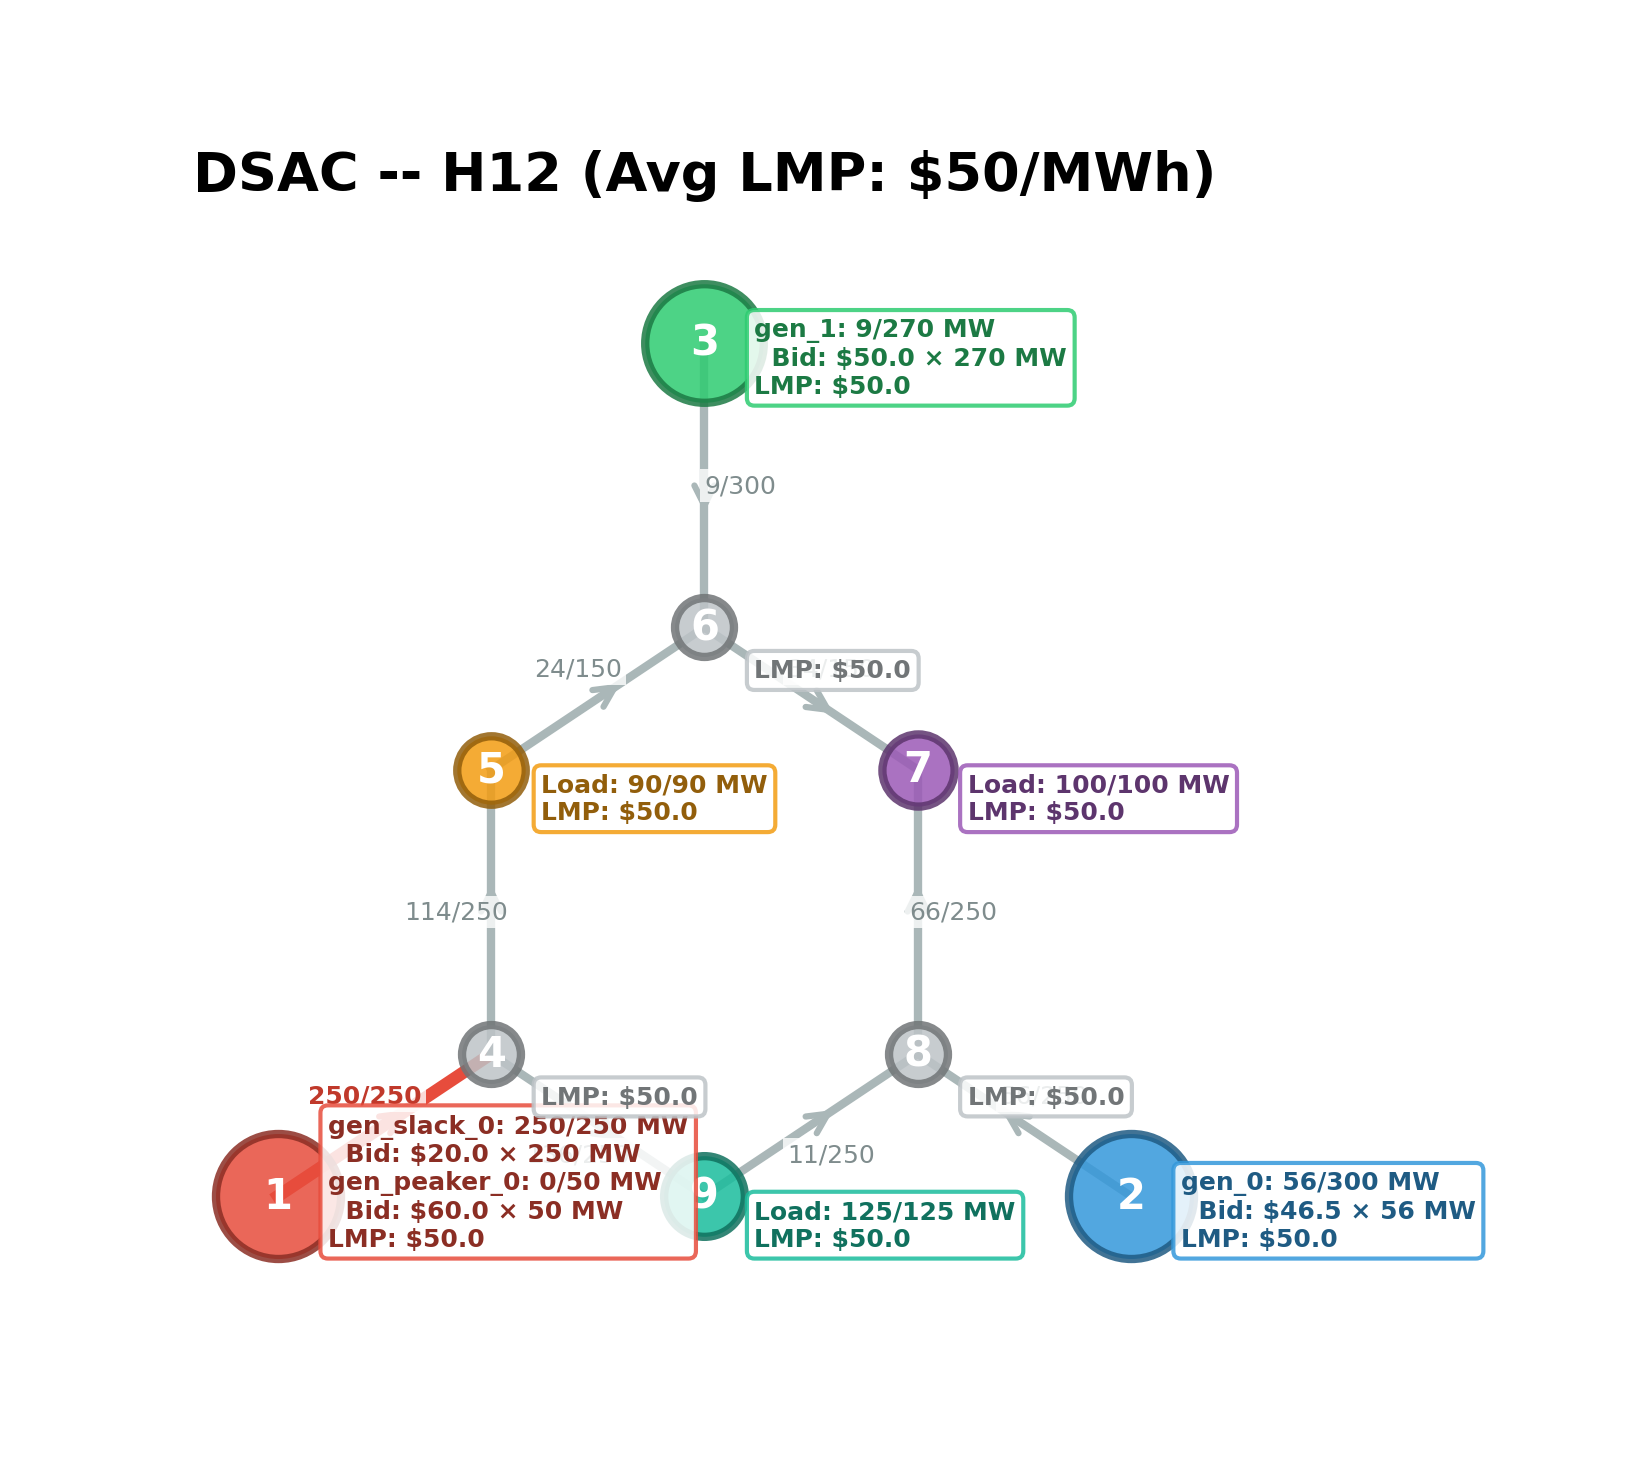

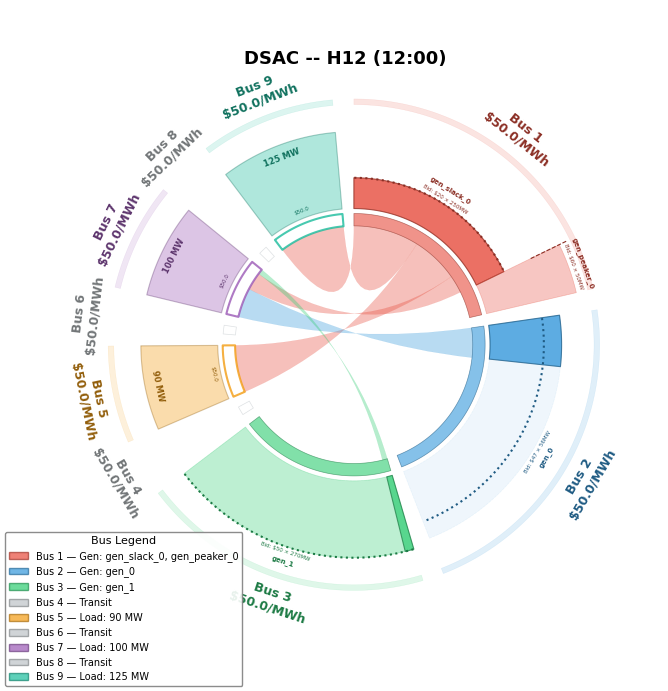

DSAC: LMPs = {'1': 50.0, '2': 50.0, '3': 50.0, '4': 50.0, '5': 50.0, '6': 50.0, '7': 50.0, '8': 50.0, '9': 50.0}



In [20]:
# ── Circlize diagrams: one per scenario at PLOT_HOUR ──────────────────────────
for scen_name in SCENARIOS:
    sd = scenario_data[scen_name]
    sr = sced_results[scen_name]
    net = sr['network']
    accepted = sr['accepted']
    rejected = sr['rejected']
    meta = sr['meta']
    flows = sr['flows']
    mkt_prods = sr['market_products']
    cfg = sd['cfg']

    all_buses = sorted(net.buses.index.tolist(), key=lambda x: int(x))
    t_start = mkt_prods[PLOT_HOUR][0]
    m = meta[PLOT_HOUR]
    avg_lmp = m['price']
    bus_lmps = m.get('bus_lmps', {})

    # Build supply/demand by bus
    supply_by_bus = {}
    demand_by_bus = {}
    demand_served = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start:
            continue
        bus = o['node']
        if o['volume'] > 0:
            if bus not in supply_by_bus:
                supply_by_bus[bus] = []
            supply_by_bus[bus].append({
                'unit_id': o['unit_id'], 'price': o['price'],
                'volume': o['volume'],
                'accepted_volume': o.get('accepted_volume', 0),
                'capacity': gen_capacity.get(o['unit_id'], o['volume']),
            })
        else:
            demand_by_bus[bus] = demand_by_bus.get(bus, 0) + abs(o['volume'])
            demand_served[bus] = demand_served.get(bus, 0) + abs(o.get('accepted_volume', 0))

    # Add missing generators
    for gn in gen_mc:
        bus = gen_bus.get(gn)
        if bus and bus in supply_by_bus:
            existing = {g['unit_id'] for g in supply_by_bus[bus]}
            if gn not in existing:
                supply_by_bus[bus].append({
                    'unit_id': gn, 'price': gen_mc[gn],
                    'volume': 0, 'accepted_volume': 0,
                    'capacity': gen_capacity.get(gn, 0),
                })
    for bus in supply_by_bus:
        supply_by_bus[bus].sort(key=lambda g: g['price'])

    # Line flows at PLOT_HOUR
    hour_flows = {ln: fl for (ln, ti), fl in flows.items() if ti == PLOT_HOUR}

    colors = assign_bus_colors(all_buses, supply_by_bus, demand_by_bus)
    flow_list = compute_ptdf_flows(net, supply_by_bus, demand_by_bus)

    # Network topology
    fig_topo, ax_topo = plot_network_topology(
        net, supply_by_bus, demand_by_bus,
        bus_colors=colors, bus_lmps=bus_lmps,
        demand_served_by_bus=demand_served,
        line_flows=hour_flows if hour_flows else None,
        title=f'{sd["label"]} -- H{PLOT_HOUR:02d} (Avg LMP: ${avg_lmp:.0f}/MWh)',
    )
    fig_topo.set_size_inches(FIG_W / 2, FIG_W / 2 * 0.8)
    plt.show()

    # Circlize
    fig_circ = plot_nodal_circlize(
        supply_by_bus, demand_by_bus, all_buses,
        flows=flow_list, clearing_price=avg_lmp, bus_lmps=bus_lmps,
        title=f'{sd["label"]} -- H{PLOT_HOUR:02d} ({t_start.strftime("%H:%M")})',
        bus_colors=colors, gen_marginal_costs=gen_mc,
    )
    fig_circ.set_size_inches(FIG_W / 2, FIG_W / 2)
    plt.show()

    print(f'{sd["label"]}: LMPs = {bus_lmps}')
    print()

## Chart 4 -- LMP & Dispatch Comparison (All Hours)

Overlaid LMP profiles and dispatch stacks for each scenario.

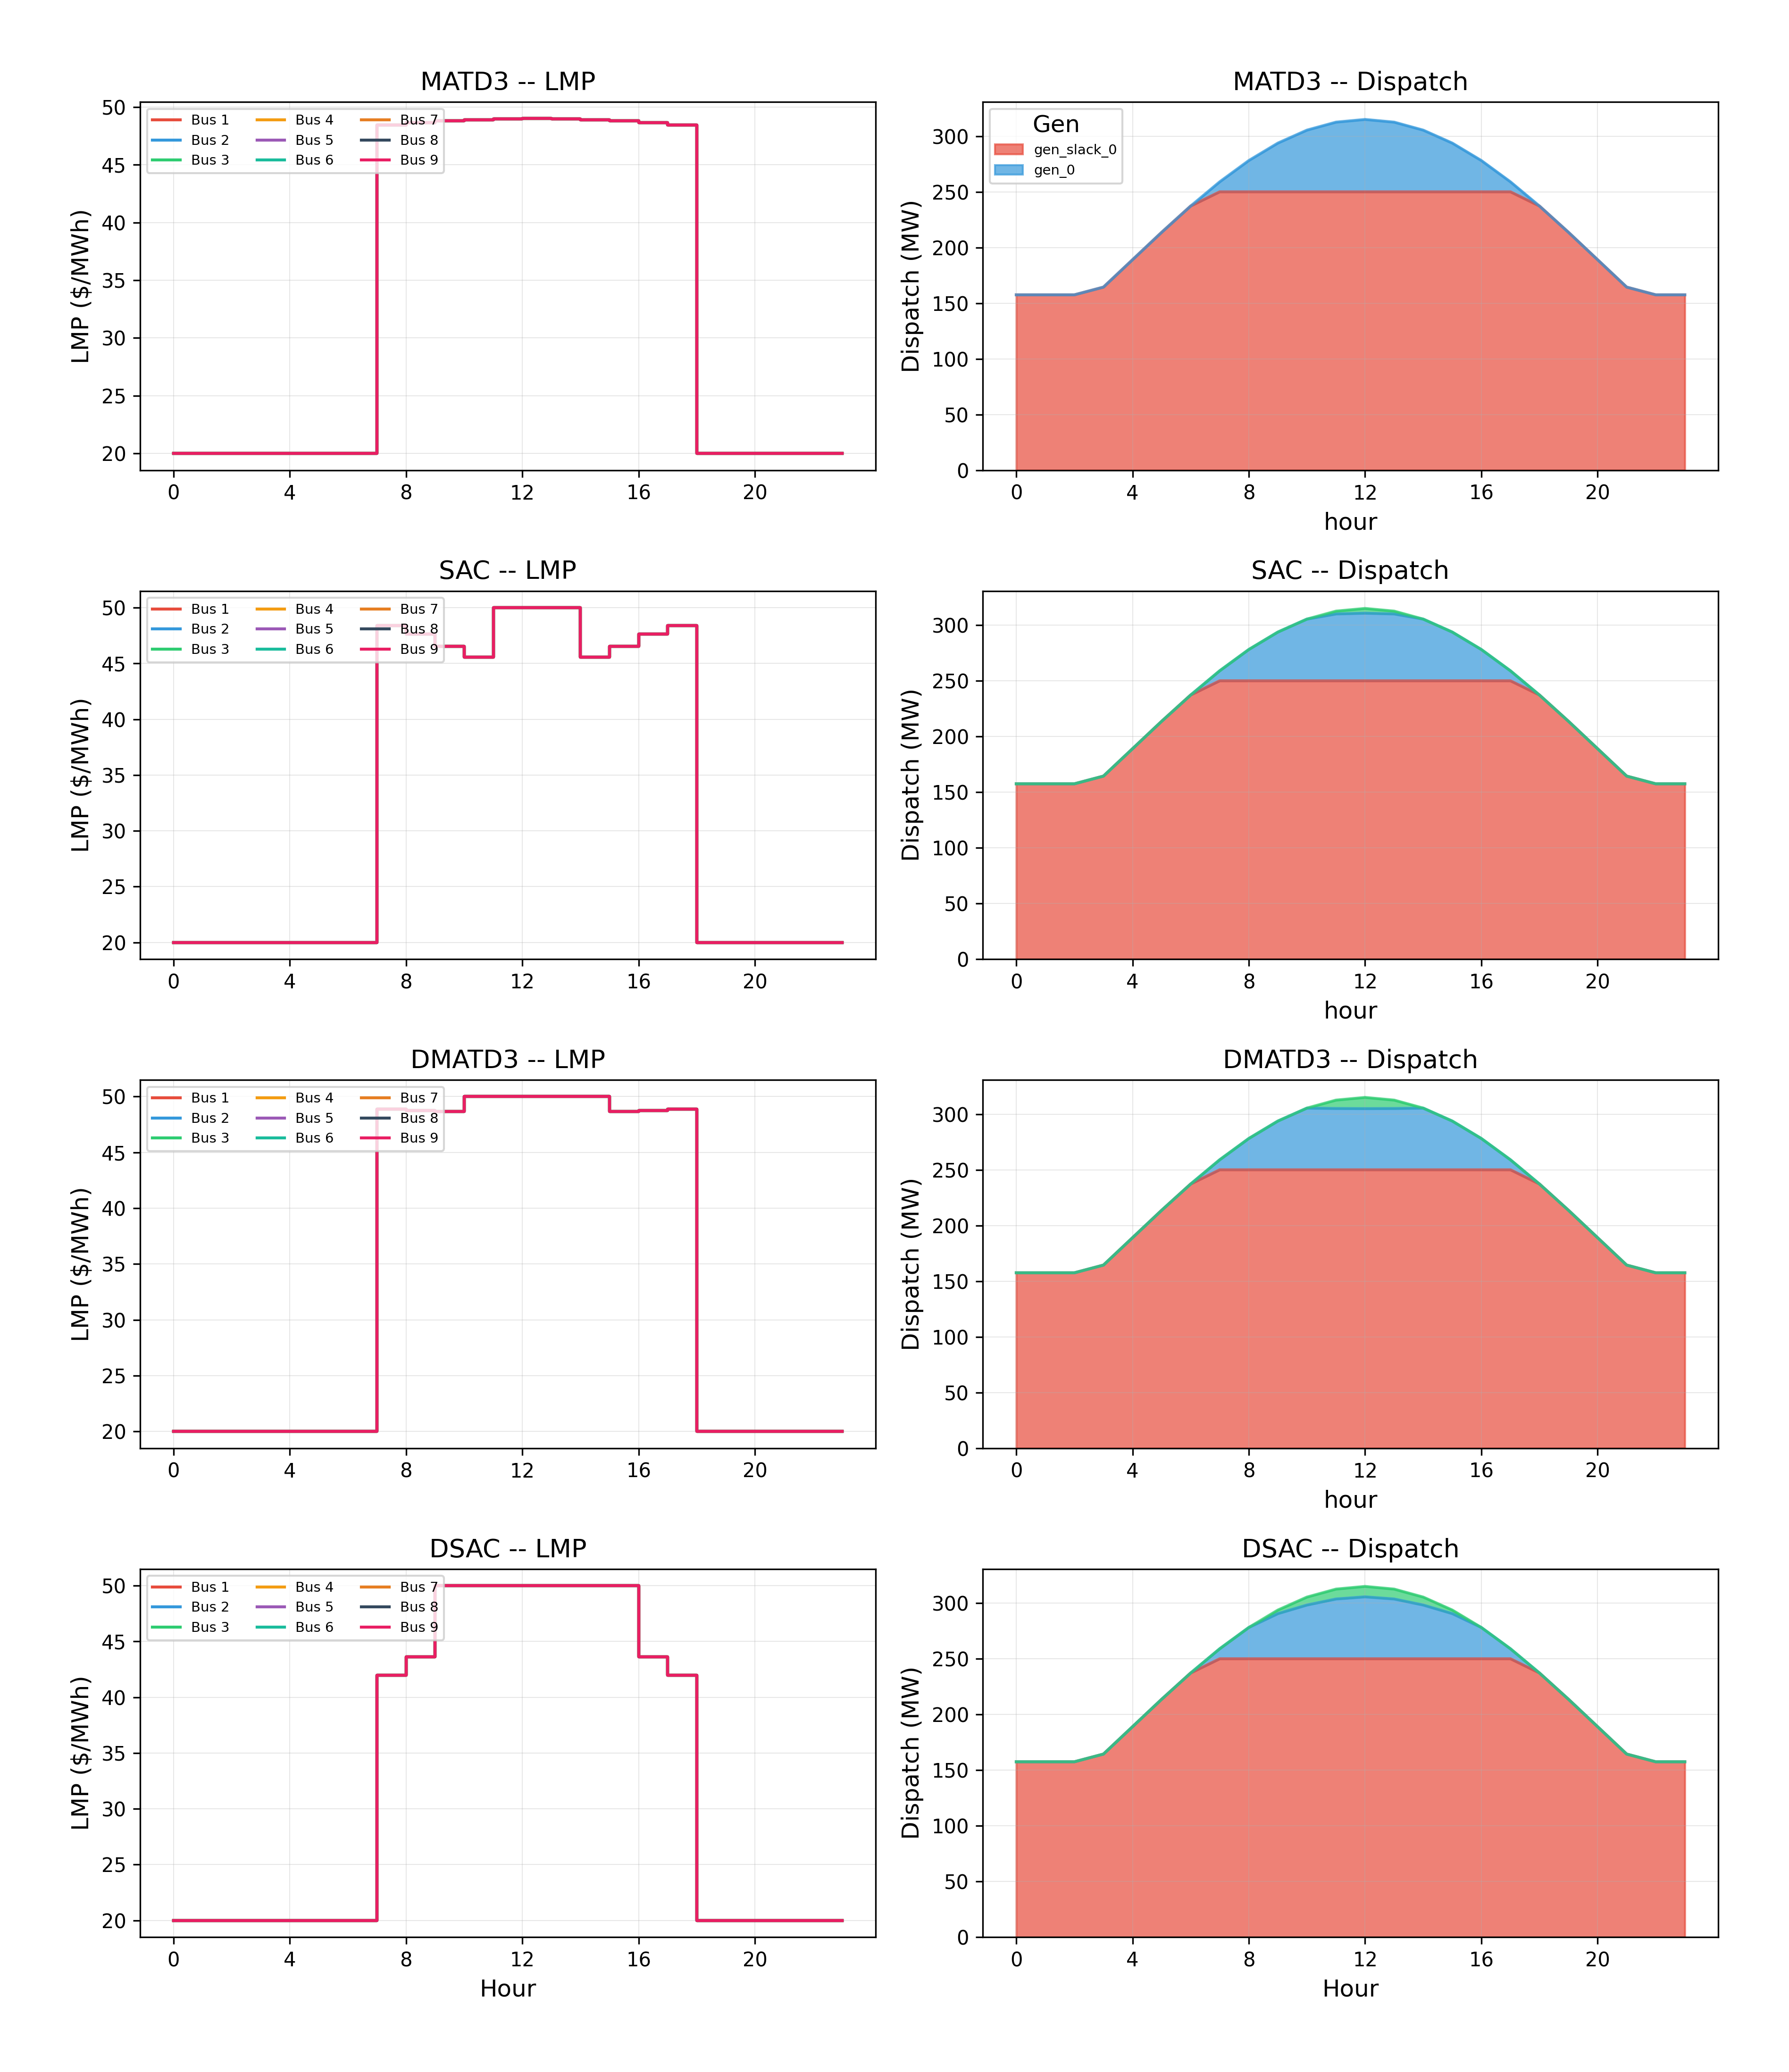

In [21]:
fig, axes = plt.subplots(len(SCENARIOS), 2, figsize=(FIG_W, 3.5 * len(SCENARIOS)),
                         gridspec_kw={'width_ratios': [1, 1]})
if len(SCENARIOS) == 1:
    axes = axes[np.newaxis, :]

for idx, scen_name in enumerate(SCENARIOS):
    sd = scenario_data[scen_name]
    sr = sced_results[scen_name]
    net = sr['network']
    accepted = sr['accepted']
    meta = sr['meta']

    all_buses = sorted(net.buses.index.tolist(), key=lambda x: int(x))

    # LMP pivot
    lmp_records = []
    for m in meta:
        hour = m['product_start'].hour
        for bus, lmp in m.get('bus_lmps', {}).items():
            lmp_records.append({'hour': hour, 'bus': bus, 'lmp': lmp})
    lmp_df = pd.DataFrame(lmp_records).drop_duplicates(subset=['hour', 'bus'])
    lmp_pivot = lmp_df.pivot(index='hour', columns='bus', values='lmp').sort_index()

    active_buses = sorted([str(b) for b in lmp_pivot.columns], key=lambda x: int(x))
    bus_cm = {}
    pi = 0
    for b in all_buses:
        if b in active_buses:
            bus_cm[b] = BUS_PALETTE[pi % len(BUS_PALETTE)]
            pi += 1
        else:
            bus_cm[b] = TRANSIT_COLOR

    # LMP panel
    ax_lmp = axes[idx, 0]
    for bus in active_buses:
        if bus in lmp_pivot.columns:
            ax_lmp.step(lmp_pivot.index, lmp_pivot[bus], where='post',
                        label=f'Bus {bus}', color=bus_cm[bus])
    ax_lmp.set_ylabel('LMP ($/MWh)')
    ax_lmp.set_title(f'{sd["label"]} -- LMP')
    ax_lmp.legend(fontsize=7, loc='upper left', ncol=3)
    ax_lmp.grid(True, alpha=0.3)
    ax_lmp.set_xticks(range(0, 24, 4))

    # Dispatch panel
    ax_disp = axes[idx, 1]
    acc_df = pd.DataFrame(accepted)
    acc_df['hour'] = acc_df['start_time'].dt.hour
    supply_acc = acc_df[acc_df['volume'] > 0].copy()
    disp_pivot = supply_acc.pivot_table(
        index='hour', columns='unit_id', values='accepted_volume',
        aggfunc='sum', fill_value=0)
    gen_order = sorted(gen_mc.keys(), key=lambda g: gen_mc[g])
    cols = [c for c in gen_order if c in disp_pivot.columns]
    gen_colors = {g: bus_cm.get(gen_bus.get(g, ''), '#888') for g in gen_order}
    disp_pivot[cols].plot.area(ax=ax_disp, alpha=0.7,
                               color=[gen_colors[c] for c in cols], legend=False)
    ax_disp.set_ylabel('Dispatch (MW)')
    ax_disp.set_title(f'{sd["label"]} -- Dispatch')
    ax_disp.set_xticks(range(0, 24, 4))
    ax_disp.grid(True, alpha=0.3)
    if idx == 0:
        ax_disp.legend(title='Gen', fontsize=7, loc='upper left')

axes[-1, 0].set_xlabel('Hour')
axes[-1, 1].set_xlabel('Hour')
plt.tight_layout()
plt.savefig(f'../testbed_results/compare_lmp_dispatch.png', bbox_inches='tight')
plt.show()

## Chart 5 -- Daily Profit Summary

Bar chart comparing total daily profit across scenarios.

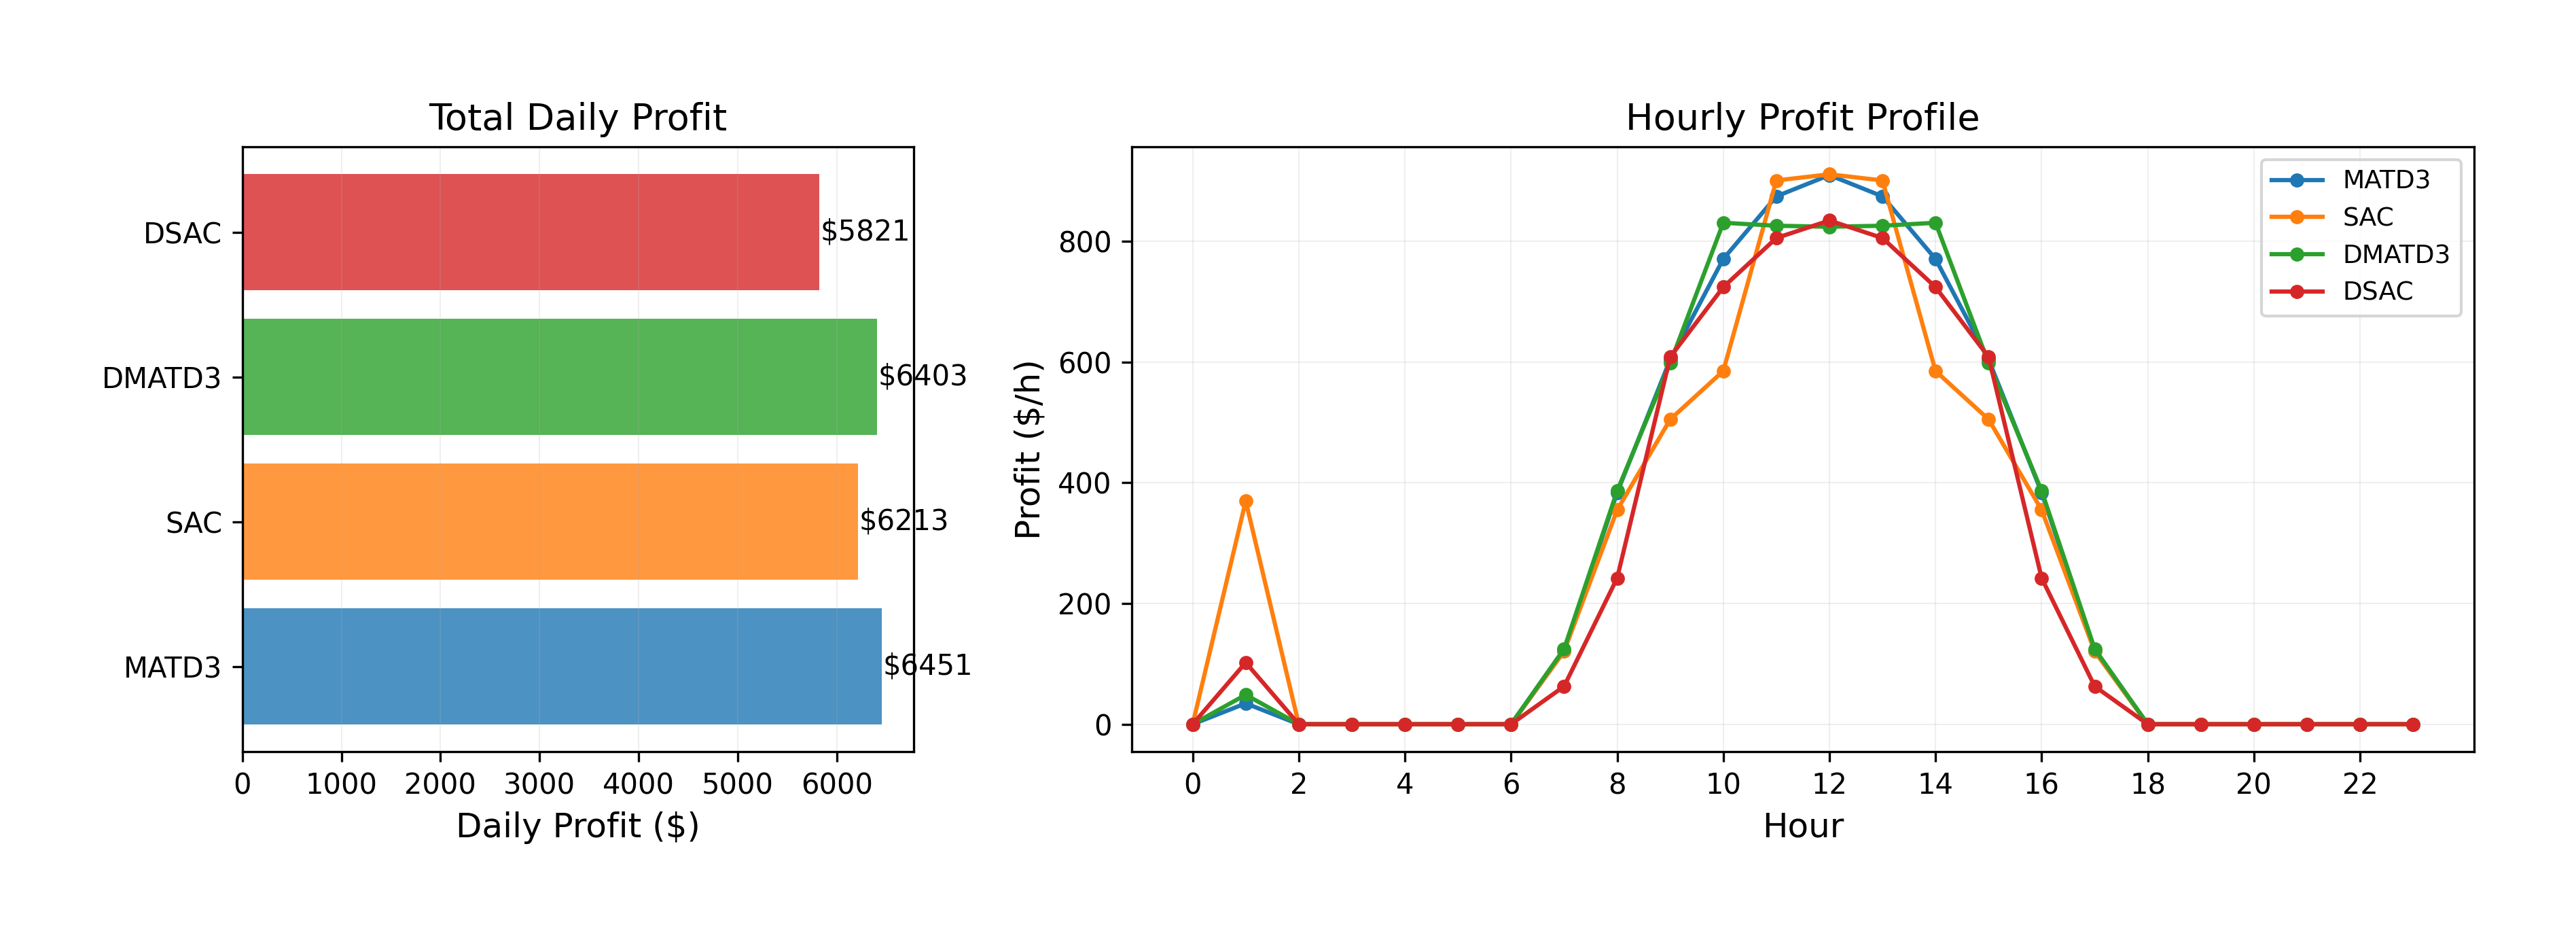


Daily profit summary:
         MATD3: $6451
        DMATD3: $6403
           SAC: $6213
          DSAC: $5821


In [22]:
daily_profits = {}
hourly_profits = {}

for scen_name in SCENARIOS:
    sd = scenario_data[scen_name]
    fr = sd['fp_results']
    if fr is None:
        continue
    rl = fr[fr['unit_id'] == FOCUS_AGENT].copy()
    rl['profit'] = (rl['accepted_price'] - rl['marginal_cost']) * rl['dispatch']
    daily_profits[sd['label']] = rl['profit'].sum()
    hourly_profits[sd['label']] = rl.set_index('hour')['profit']

# Bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_W, 4),
                                gridspec_kw={'width_ratios': [1, 2]})

labels = list(daily_profits.keys())
values = list(daily_profits.values())
colors = [scenario_data[s]['color'] for s in SCENARIOS if scenario_data[s]['label'] in labels]

ax1.barh(labels, values, color=colors, alpha=0.8)
ax1.set_xlabel('Daily Profit ($)')
ax1.set_title('Total Daily Profit')
for i, v in enumerate(values):
    ax1.text(v + 10, i, f'${v:.0f}', va='center', fontsize=FONT_TICK)
ax1.grid(True, alpha=0.2, axis='x')

# Hourly profit comparison
for label, hp in hourly_profits.items():
    color = [scenario_data[s]['color'] for s in SCENARIOS if scenario_data[s]['label'] == label][0]
    ax2.plot(hp.index, hp.values, '-o', color=color, label=label, markersize=4)
ax2.set_xlabel('Hour')
ax2.set_ylabel('Profit ($/h)')
ax2.set_title('Hourly Profit Profile')
ax2.legend(fontsize=FONT_LEGEND)
ax2.grid(True, alpha=0.2)
ax2.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig(f'../testbed_results/compare_profit.png', bbox_inches='tight')
plt.show()

print('\nDaily profit summary:')
for label, val in sorted(daily_profits.items(), key=lambda x: -x[1]):
    print(f'  {label:>12s}: ${val:.0f}')